# Planejar e Executar


## Configuração

In [1]:
# %%capture --no-stderr
# %pip install --quiet -U langgraph langchain-community langchain-google-genai tavily-python python-dotenv

In [2]:
import os
import getpass
import pandas as pd
from typing import List, Annotated, Literal
from typing_extensions import TypedDict
import operator
from dotenv import load_dotenv

from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_community.vectorstores import SKLearnVectorStore
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_community.tools.tavily_search import TavilySearchResults
from pydantic import BaseModel, Field
from langchain_community.document_loaders import WebBaseLoader
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display
from langchain_core.vectorstores import InMemoryVectorStore

from langchain_google_genai import ChatGoogleGenerativeAI
from pydantic import BaseModel, Field
from typing import Literal


# Set API keys
def _set_env(var: str):
    if not os.environ.get(var):
        os.environ[var] = getpass.getpass(f"{var}: ")

_set_env("GEMINI_API_KEY")
_set_env("TAVILY_API_KEY")
load_dotenv()

print("✅ Ambiente pronto.")

c:\Users\sirja\venv\Lib\site-packages\langchain_core\utils\pydantic.py:41: UserWarning: Core Pydantic V1 functionality isn't compatible with Python 3.14 or greater.
  from pydantic.v1 import BaseModel as BaseModelV1
USER_AGENT environment variable not set, consider setting it to identify your requests.


✅ Ambiente pronto.


## 1. Carregar e indexar os tickets

In [3]:
# Carrega o DataFrame processado (gerado pelo ColetaProcessamentoDados.ipynb)
df_tickets = pd.read_csv("df_tickets.csv")
print(f"📊 Total de tickets carregados: {len(df_tickets)}")
print(f"Colunas: {df_tickets.columns.tolist()}")

def criar_documentos_ticket(df):
    """Converte cada ticket em um documento para busca semântica."""
    docs = []
    for _, row in df.iterrows():
        # Converte a string de tags para lista
        tags = row['todas_tags']
        if isinstance(tags, str):
            try:
                tags = eval(tags)
            except:
                tags = []
        # Conteúdo textual do ticket
        content = f"""
        Assunto: {row['assunto']}
        Descrição: {row['descricao']}
        Resposta: {row['resposta']}
        Tipo: {row['tipo']}
        Prioridade: {row['prioridade']}
        Fila: {row['fila']}
        Idioma: {row['idioma']}
        Tags: {', '.join(tags)}
        """
        metadata = {
            "assunto": row['assunto'],
            "tipo": row['tipo'],
            "prioridade": row['prioridade'],
            "fila": row['fila'],
            "idioma": row['idioma']
        }
        docs.append(Document(page_content=content.strip(), metadata=metadata))
    return docs

df_sample = df_tickets.sample(n=200, random_state=42)
ticket_docs = criar_documentos_ticket(df_sample)
print(f"📄 Documentos criados: {len(ticket_docs)}")

📊 Total de tickets carregados: 22066
Colunas: ['assunto', 'fila', 'descricao', 'tipo', 'resposta', 'prioridade', 'todas_tags', 'idioma', 'descricao_length']
📄 Documentos criados: 200


In [4]:
# Embeddings e vectorstore
embeddings = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")
vetortickets = SKLearnVectorStore.from_documents(
    documents=ticket_docs,
    embedding=embeddings,
)
recuperadorTickets = vetortickets.as_retriever(search_kwargs={"k": 4})
print("✅ Vectorstore criado e pronto para buscas.")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

✅ Vectorstore criado e pronto para buscas.


## 2 Carregar e indexar Referencias

In [5]:

urls = [
    "https://itsmnapratica.com.br/tudo-sobre-itil/",
    "https://www.estrategiaconcursos.com.br/blog/resumo-itil-4-iss-sp/",
    "https://www.ibm.com/br-pt/think/topics/it-infrastructure-library",
]

# Carregar documentos
docs = [WebBaseLoader(url).load() for url in urls]
docs_list = [item for sublist in docs for item in sublist]

# Dividir em chunks
text_splitter = RecursiveCharacterTextSplitter.from_tiktoken_encoder(
    chunk_size=500, chunk_overlap=50
)
doc_splits = text_splitter.split_documents(docs_list)

# Criar vectorstore com embeddings locais
embeddings = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")
vectorstore = InMemoryVectorStore.from_documents(documents=doc_splits, embedding=embeddings)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [6]:
from langchain_core.documents import Document

# Dados dos tickets
gabaritos = [
    {
        "Ticket": "1",
        "Assunto": "Lentidão na pesquisa do histórico de um cliente no CRM",
        "Descrição": "quando estou pesquisando o histórico do cliente Lojas Compra Mais, o CRM demora mais de 10 segundos para retornar os dados, o que inviabiliza o uso e parte das operações que preciso realizar diariamente.",
        "Solução": "sob a ótica da TI o tempo é condizente com a operação. Como não existe um objetivo ou métrica padrão definida para essa operação, entendemos que não existe problema com o serviço disponibilizado.",
        "Prática ITIL que evitaria esse incidente e poderia resolver o problema previamente": "Gerenciamento de Nível de Serviço e Gerenciamento de Disponibilidade",
    },
    {
        "Ticket": "2",
        "Assunto": "Falha no processo de contato com leads no CRM",
        "Descrição": "no nosso processo comercial, após a segunda abordagem à um lead, precisamos nutri-lo com informações sobre nossos serviços, bem como enviar cases relacionados à sua atuação. Porém, no processo do CRM, após a segunda abordagem o lead é classificado como se não tivesse interesse nos nossos serviços. Isso vem causando uma dificuldade no nosso fluxo de atividades, poderiam realizar o ajuste?",
        "Solução": "infelizmente, alterar o processo do nosso CRM demandará um prazo e terá um custo (que será repassado para o orçamento da área comercial). Isso ocorre porque na reunião de definição que tivemos, embora ela tenha sido verbal e a análise realizada em nível macro, essa situação não foi destacada. Vamos solicitar os ajustes ao fornecedor do software.",
        "Prática ITIL que evitaria esse incidente e poderia resolver o problema previamente": "Análise de Negócio",
    },
    {
        "Ticket": "3",
        "Assunto": "Indisponibilidade dos dashboards de BI quando acessados via navegador",
        "Descrição": "até ontem eu estava acessando normalmente meu conjunto de dashboards de BI chamado “Análises Financeiras”, porém, hoje pela manhã, ao tentar acessar pelo navegador retorna uma mensagem de indisponibilidade dos serviços de BI. Poderiam me ajudar?",
        "Solução": "o problema ocorreu porque ao instalarmos uma nova dll relacionada a uma atualização do software de CRM, gerou uma incompatibilidade com alguns serviços de BI, pois ambos os serviços (BI e CRM) compartilham o mesmo servidor de autenticação. Estamos voltando a versão do software de CRM e até o final do dia os serviços de BI devem estar disponíveis novamente.",
        "Prática ITIL que evitaria esse incidente e poderia resolver o problema previamente": "Controle de Mudanças",
    },
    {
        "Ticket": "4",
        "Assunto": "levantamento de licenças",
        "Descrição": "preciso saber quantas licenças temos atualmente em uso do software Autocad 2025, pois vamos analisar a atualização das versões e precisamos identificar o custo total da demanda.",
        "Solução": "vamos fazer um levantamento (inventário) e retornamos esse chamado com a informações em 5 dias úteis",
        "Prática ITIL que evitaria esse incidente e poderia resolver o problema previamente": "Gerenciamento de Ativos de TI",
    }
]

In [7]:
# Criar uma lista de Document a partir dos tickets
ticket_documents = []
for ticket in gabaritos:
    # O texto principal que será usado para busca (page_content)
    content = f"""
    Ticket {ticket['Ticket']}: {ticket['Assunto']}
    Descrição: {ticket['Descrição']}
    Solução: {ticket['Solução']}
    Prática ITIL sugerida: {ticket['Prática ITIL que evitaria esse incidente e poderia resolver o problema previamente']}
    """
    # Metadados úteis para filtragem posterior
    metadata = {
        "tipo": "ticket",
        "numero": ticket["Ticket"],
        "assunto": ticket["Assunto"],
        "pratica_itil": ticket["Prática ITIL que evitaria esse incidente e poderia resolver o problema previamente"]
    }
    doc = Document(page_content=content.strip(), metadata=metadata)
    ticket_documents.append(doc)

# Adicionar os tickets ao vectorstore existente (InMemoryVectorStore)
vectorstore.add_documents(ticket_documents)

# O recuperador continua o mesmo, agora com os tickets também indexados
recuperador = vectorstore.as_retriever(search_kwargs={"k": 5})  # opcional: aumentar k

print(f"Documentos carregados: {len(doc_splits)}")

Documentos carregados: 76


## Definir Ferramentas

In [8]:
from langchain_community.tools.tavily_search import TavilySearchResults

tools = [TavilySearchResults(max_results=3)]

C:\Users\sirja\AppData\Local\Temp\ipykernel_16432\2518516040.py:3: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  tools = [TavilySearchResults(max_results=3)]


# Definir nosso Agente de Execução

Agora vamos criar o agente de execução que queremos usar para executar tarefas.
Observe que, para este exemplo, usaremos o mesmo agente de execução para cada tarefa, mas isso NÃO PRECISA ser o caso.

In [9]:
import os
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain.agents import create_agent
from langchain_core.messages import HumanMessage

llm = ChatGoogleGenerativeAI(
    model="gemini-3-flash-preview", 
    temperature=0.3, 
    google_api_key=os.environ.get("GEMINI_API_KEY") 
)

prompt_sistema = """Você é um agente especialista em service desk. 
Sua função é analisar chamados de suporte de TI, categorizá-los corretamente utilizando as práticas do ITIL v4, e buscar informações relevantes para propor soluções aos usuários."""

agent_executor = create_agent(
    model=llm,
    tools=tools, 
    system_prompt=prompt_sistema 
) 

prompt_sistema_rag = """Você é um agente focado em analisar tickets de TI e avaliar quais práticas da ITIL v4 são mais relevantes para resolver os problemas descritos nos tickets.
Para isso, você tem acesso a um banco de dados de tickets históricos, onde pode buscar por tickets similares ao que está analisando. 
Sua tarefa é:
1. Analisar os tickets históricos encontrados.
2. Identificar qual foi a solução ou padrão de solução aplicado neles.
3. Com base neles e no seu conhecimento, Indicar qual ou quais prática da ITIL v4 deve ser aplicada para gerenciar/evitar esse problema.
"""

agent_rag_adaptativo = create_agent(
    model=llm,
    tools=tools,
    system_prompt=prompt_sistema_rag
)

## Definir o Estado

Vamos começar definindo o estado a ser rastreado para este agente.

Primeiro, precisaremos rastrear o plano atual. Vamos representá-lo como uma lista de strings.

Em seguida, devemos rastrear as etapas executadas anteriormente. Vamos representá-las como uma lista de tuplas (essas tuplas conterão a etapa e, em seguida, o resultado).

Finalmente, precisamos ter algum estado para representar a resposta final, bem como a entrada original.

In [10]:
import operator
from typing import Annotated, List, Tuple,Optional
from typing_extensions import TypedDict

class PlanExecute(TypedDict):
    input: str
    plan: List[str]
    past_steps: Annotated[List[Tuple], operator.add]
    response: Optional[str]
    documents: Annotated[List, operator.add]        # usado pelo ciclo RAG
    generation: Optional[str]        # resposta gerada no passo atual
    loop_step: Optional[int]         # contador de tentativas
    pesquisa_web: Optional[str]      # sinaliza necessidade de busca web
    max_retries: Optional[int]       # limite de retentativas contra alucinação

## Etapa Avaliação

In [11]:
from langchain_core.prompts import PromptTemplate
# Schema para roteador
class RespostaRota(BaseModel):
    datasource: Literal["websearch", "vectorstore"] = Field(
        description="Fonte a ser usada: 'websearch' para pesquisa na web, 'vectorstore' para base de documentos"
    )

In [12]:
prompt_sistema_rag = """Você é um especialista em rotear perguntas.

Você receberá uma pergunta de um usuário e deve decidir se ela deve ser respondida usando:
- 'vectorstore': para perguntas sobre ITIL, gerenciamento de serviços de TI, boas práticas de TI
- 'websearch': para perguntas gerais, eventos atuais, notícias, ou tópicos fora do escopo de ITIL

Pergunta do usuário: {question}

Retorne o datasource apropriado."""

rag_prompt_structured = PromptTemplate.from_template(prompt_sistema_rag) | ChatGoogleGenerativeAI(
    model="gemini-3.1-flash-lite-preview",
    temperature=0,
    google_api_key=os.environ.get("GEMINI_API_KEY")
).with_structured_output(RespostaRota)

In [13]:


# Defina a string do prompt
rag_prompt_str = """Você é um assistente para tarefas de resposta a perguntas.

Aqui está o contexto a ser usado para responder à pergunta:

{context}

Pergunta do usuário: {question}

Forneça uma resposta a esta pergunta usando **apenas** o contexto acima.
Use no máximo três frases e mantenha a resposta concisa.
Se o contexto não contiver informações suficientes, diga que não sabe.

Resposta:"""

# Converta para PromptTemplate
rag_prompt = PromptTemplate.from_template(rag_prompt_str)

# Agora o LCEL funcionará corretamente
rag_llm = rag_prompt | ChatGoogleGenerativeAI(
    model="gemini-3.1-flash-lite-preview", 
    temperature=0,
    google_api_key=os.environ.get("GEMINI_API_KEY")
).with_structured_output(RespostaRota)

In [14]:
# Schema para avaliador de documentos
class ClassificacaoDocumentos(BaseModel):
    binary_score: Literal["sim", "não"] = Field(
        description="'sim' se o documento é relevante para a pergunta, 'não' caso contrário"
    )

In [15]:
# Prompt do avaliador de documentos atualizado
doc_avaliador_prompt = """Você é um avaliador que verifica a relevância de um documento para uma pergunta.

Pergunta do usuário: {question}
Documento recuperado: {document}

Se o documento contiver palavras-chave ou significado semântico relacionado à pergunta, classifique como relevante.
Responda apenas com 'sim' ou 'não'."""

avaliador_documentos = PromptTemplate.from_template(doc_avaliador_prompt) | ChatGoogleGenerativeAI(
    model="gemini-3.1-flash-lite-preview",
    temperature=0,
    google_api_key=os.environ.get("GEMINI_API_KEY")
).with_structured_output(ClassificacaoDocumentos)

In [16]:
# Schema para avaliador de alucinações
class ClassificacaoAlucinacoes(BaseModel):
    binary_score: Literal["sim", "não"] = Field(
        description="'sim' se a resposta está fundamentada nos fatos, 'não' se contém alucinações"
    )
    explanation: str = Field(description="Explicação da pontuação")

In [17]:
classificador_alucinacoes_prompt = """FATOS:\n\n{documents}\n\nRESPOSTA DO ALUNO:\n{generation}

A resposta está fundamentada nos fatos?"""

classificador_alucinacoes = PromptTemplate.from_template(classificador_alucinacoes_prompt) | ChatGoogleGenerativeAI(
    model="gemini-3.1-flash-lite-preview",  
    temperature=0,
    google_api_key=os.environ.get("GEMINI_API_KEY")
).with_structured_output(ClassificacaoAlucinacoes)

## Etapa de Planejamento

Agora, vamos pensar em criar a etapa de planejamento. Isso usará a chamada de função para criar um plano.

In [18]:
from pydantic import BaseModel, Field


class Plan(BaseModel):
    """Plano a seguir no futuro"""

    steps: List[str] = Field(
        description="diferentes etapas a seguir, devem estar em ordem classificadas"
    )

In [19]:
from langchain_core.prompts import ChatPromptTemplate

planejador_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            """Para o objetivo dado, crie um plano simples passo a passo. \
Este plano deve envolver tarefas individuais que, se executadas corretamente, fornecerão a resposta correta. Não adicione etapas supérfluas. \
O resultado da etapa final deve ser a resposta final. Certifique-se de que cada etapa tenha todas as informações necessárias - não pule etapas.""",
        ),
        ("placeholder", "{messages}"),
    ]
)
planejador = planejador_prompt | ChatGoogleGenerativeAI(
    model="gemini-3-flash-preview", 
    temperature=0, 
    google_api_key=os.environ.get("GEMINI_API_KEY") 
).with_structured_output(Plan)

## Etapa de Replanejamento

Agora, vamos criar uma etapa que refaz o plano com base no resultado da etapa anterior.

In [20]:
from typing import Union


class Response(BaseModel):
    """Resposta ao usuário."""

    response: str


class Act(BaseModel):
    """Ação a ser executada."""

    action: Union[Response, Plan] = Field(
        description="Ação a ser executada. Se você deseja responder ao usuário, use Resposta. "
        "Se precisar usar mais ferramentas para obter a resposta, use Plano."
    )


replanejador_prompt = ChatPromptTemplate.from_template(
    """Para o objetivo dado, crie um plano simples passo a passo. \
Este plano deve envolver tarefas individuais que, se executadas corretamente, fornecerão a resposta correta. Não adicione etapas supérfluas. \
O resultado da etapa final deve ser a resposta final. Certifique-se de que cada etapa tenha todas as informações necessárias - não pule etapas.

Seu objetivo foi este:
{input}

Seu plano original foi este:
{plan}

Você completou os seguintes passos:
{past_steps}

Atualize seu plano de acordo. Se não houver mais etapas necessárias e você puder retornar ao usuário, então responda com isso. Caso contrário, preencha o plano. Adicione apenas as etapas ao plano que AINDA PRECISAM ser feitas. Não retorne etapas já concluídas como parte do plano."""
)


replanejador = replanejador_prompt | ChatGoogleGenerativeAI(
    model="gemini-3-flash-preview", 
    temperature=0.3, 
    google_api_key=os.environ.get("GEMINI_API_KEY") 
).with_structured_output(Act)

## Criar o Grafo

## Passos

In [21]:
from langchain_core.messages import SystemMessage, HumanMessage
from langchain_community.tools.tavily_search import TavilySearchResults
from langgraph.graph import END

# Ferramenta de busca web
web_search_tool = TavilySearchResults(k=3)

def formatar_documentos(docs):
    return "\n\n".join(doc.page_content for doc in docs)

async def recuperar(state: PlanExecute):
    """Recupera documentos do vectorstore"""
    print("---RECUPERAR DO VECTORSTORE---")
    question = state["input"]
    documents = await recuperador.ainvoke(question)
    return {"documents": documents}

async def pesquisa_web(state: PlanExecute):
    """Pesquisa na web"""
    print("---PESQUISA NA WEB---")
    question = state["input"]
    documents = state.get("documents", [])
    
    results = await web_search_tool.ainvoke({"query": question})
    # Converter resultados para formato Document
    from langchain_core.documents import Document
    web_docs = [Document(page_content=r["content"], metadata={"source": r.get("url", "web")}) for r in results]
    documents.extend(web_docs)
    return {"documents": documents}

async def gerar(state: PlanExecute):
    print("--- GERANDO RESPOSTA ---")
    question = state["input"]
    docs = state.get("documents", [])
    context = "\n\n".join(doc.page_content for doc in docs)
    prompt = f"""Com base no seguinte contexto:
{context}

Pergunta: {question}

Responda de forma concisa, citando as práticas ITIL v4 relevantes."""
    result = await agent_rag_adaptativo.ainvoke([HumanMessage(content=prompt)])
    return {
        "generation": result.content,
        "loop_step": state.get("loop_step", 0) + 1
    }

    # Retorna o texto na chave "generation" que o avaliador espera
    return {
        "generation": res_text,
        "loop_step": state.get("loop_step", 0) + 1 # Incrementa o contador
    }

async def avaliar_documentos(state: PlanExecute):
    """Avalia relevância dos documentos"""
    print("---AVALIAR RELEVÂNCIA DOS DOCUMENTOS---")
    question = state["input"]
    documents = state["documents"]

    filtered_docs = []
    web_search_needed = "Não"
    
    # Substitua o bloco 'for doc in documents:' do seu nó 'avaliar_documentos' por este:
    for doc in documents:
        # CORREÇÃO: Passar o dicionário de variáveis diretamente para a chain
        result = await avaliador_documentos.ainvoke({
            "document": doc.page_content, 
            "question": question
        })
        grade = result.binary_score
        
        if grade == "sim":
            print("---DOCUMENTO RELEVANTE---")
            filtered_docs.append(doc)
        else:
            print("---DOCUMENTO NÃO RELEVANTE---")
            web_search_needed = "Sim"
    
    return {"documents": filtered_docs, "pesquisa_web": web_search_needed}

async def rotear_pergunta(state: PlanExecute):
    """Roteia a pergunta para vectorstore ou websearch"""
    print("---ROTEAR PERGUNTA---")
    
    # CORREÇÃO: Invocar a chain estruturada, passando a pergunta
    result = await rag_prompt_structured.ainvoke({"question": state["input"]})
    
    source = result.datasource
    if source == "websearch":
        print("---ROTEANDO PARA PESQUISA NA WEB---")
        return "websearch"
    else:
        print("---ROTEANDO PARA VECTORSTORE---")
        return "recuperar"

async def decidir_gerar(state: PlanExecute):
    """Decide se gera resposta ou busca na web após avaliação"""
    print("---DECIDIR PRÓXIMO PASSO---")
    if state.get("pesquisa_web") == "Sim":
        print("---DOCUMENTOS INSUFICIENTES, BUSCAR NA WEB---")
        return "websearch"
    else:
        print("---DOCUMENTOS RELEVANTES, GERAR RESPOSTA---")
        return "gerar"

async def avaliar_geracao_vs_documentos_e_pergunta(state: PlanExecute):
    """Verifica alucinação e se resposta responde à pergunta"""
    print("---VERIFICAR ALUCINAÇÕES---")
    question = state["input"]
    documents = state.get("documents", [])
    generation = state.get("generation", "")
    max_retries = state.get("max_retries", 3)
    loop_step = state.get("loop_step", 1)

    # 1. Verificar alucinação (CORREÇÃO: Passando dicionário)
    docs_txt = formatar_documentos(documents)
    result = await classificador_alucinacoes.ainvoke({
        "documents": docs_txt, 
        "generation": generation
    })
    hallucination_grade = result.binary_score
    print(f"Alucinação: {hallucination_grade} - {result.explanation}")

    if hallucination_grade == "não":
        if loop_step <= max_retries:
            print("---ALUCINAÇÃO DETECTADA, TENTAR NOVAMENTE---")
            return "nao suportado"
        else:
            print("---MÁXIMO DE TENTATIVAS ATINGIDO---")
            return "max_retries"

  
   
    print("---VERIFICAR SE RESPOSTA RESPONDE À PERGUNTA---")
    
    prompt_utilidade = f"""A seguinte resposta: '{generation}' 
Responde adequadamente à pergunta original: '{question}'?
Responda APENAS em formato JSON contendo a chave "binary_score" com os valores "sim" ou "não"."""
    
    response = await llm.ainvoke([HumanMessage(content=prompt_utilidade)])
    
    import json
    try:
        # Quando usamos o 'llm' bruto, acessamos a resposta com .content
        content = response.content
        start = content.find('{')
        end = content.rfind('}') + 1
        if start != -1 and end != 0:
            json_str = content[start:end]
            data = json.loads(json_str)
            answer_grade = data.get("binary_score", "não").lower()
        else:
            answer_grade = "não"
    except:
        answer_grade = "não"

    if answer_grade == "sim": # Se NÃO há alucinação (ajuste conforme seu prompt)
            return "util"
    elif answer_grade == "não" :
            return "nao util"
    else:
        return "nao suportado"
    
    

In [22]:
from typing import Literal
from langgraph.graph import END


async def passo_executar(state: PlanExecute):
    plan_obj = state["plan"]
    # Handle Plan object: extract steps
    if hasattr(plan_obj, 'steps'):
        plan = plan_obj.steps
    elif isinstance(plan_obj, dict) and 'steps' in plan_obj:
        plan = plan_obj['steps']
    else:
        plan = plan_obj if isinstance(plan_obj, list) else [plan_obj]
    plan_str = "\n".join(f"{i + 1}. {step}" for i, step in enumerate(plan))
    task = plan[0]
    task_formatted = f"""Para o seguinte plano:
{plan_str}\n\nVocê tem a tarefa de executar o passo {1}, {task}."""
    agent_response = await agent_executor.ainvoke(
        {"messages": [("user", task_formatted)]}
    )
    return {
        "past_steps": [(task, agent_response["messages"][-1].content)],
    }


async def passo_planejar(state: PlanExecute):
    plan = await planejador.ainvoke({"messages": [("user", state["input"])]})
    if isinstance(plan, dict) and "steps" in plan:
        return {"plan": plan["steps"]}
    return {"plan": plan}


async def passo_replanejar(state: PlanExecute):
    output = await replanejador.ainvoke(state)
    if isinstance(output.action, Response):
        return {"response": output.action.response}
    else:
        return {"plan": output.action.steps}


def deve_finalizar(state: PlanExecute):
    if "response" in state and state["response"]:
        return "gerar"
    else:
        return "agent"

In [23]:
from langgraph.graph import StateGraph, START, END

workflow = StateGraph(PlanExecute)

# Adiciona o nó do plano
workflow.add_node("planejador", passo_planejar)

# Adiciona a etapa de execução
workflow.add_node("agent", passo_executar)

# Adiciona um nó de replanejamento
workflow.add_node("replanejar", passo_replanejar)

workflow.add_node("recuperar", recuperar)
workflow.add_node("websearch", pesquisa_web)
workflow.add_node("avaliar_documentos", avaliar_documentos)
workflow.add_node("gerar", gerar)

workflow.add_edge(START, "planejador")

# Do plano, vamos para o agente
workflow.add_edge("planejador", "agent")

# Do agente, replanejamos
workflow.add_edge("agent", "replanejar")

workflow.add_conditional_edges(
    "replanejar",
    # Em seguida, passamos a função que determinará qual nó será chamado em seguida.
    deve_finalizar,
    ["agent", "gerar"],
)

# Após websearch, ir direto para gerar
# Após gerar, verificar qualidade
workflow.add_conditional_edges(
    "gerar",
    avaliar_geracao_vs_documentos_e_pergunta,
    {
        "nao suportado": "gerar",
        "util": END,
        "nao util": "websearch",
        "max_retries": END,
    }
)
# Após recuperar, avaliar documentos
workflow.add_edge("recuperar", "avaliar_documentos")

# Após avaliar documentos, decidir próximo passo
workflow.add_conditional_edges(
    "avaliar_documentos",
    decidir_gerar,
    {
        "websearch": "websearch",
        "gerar": "gerar",
    }
)


workflow.add_edge("gerar", END)  # se resposta não útil, volta para replanejador
# 
# Compilação do App
app = workflow.compile()

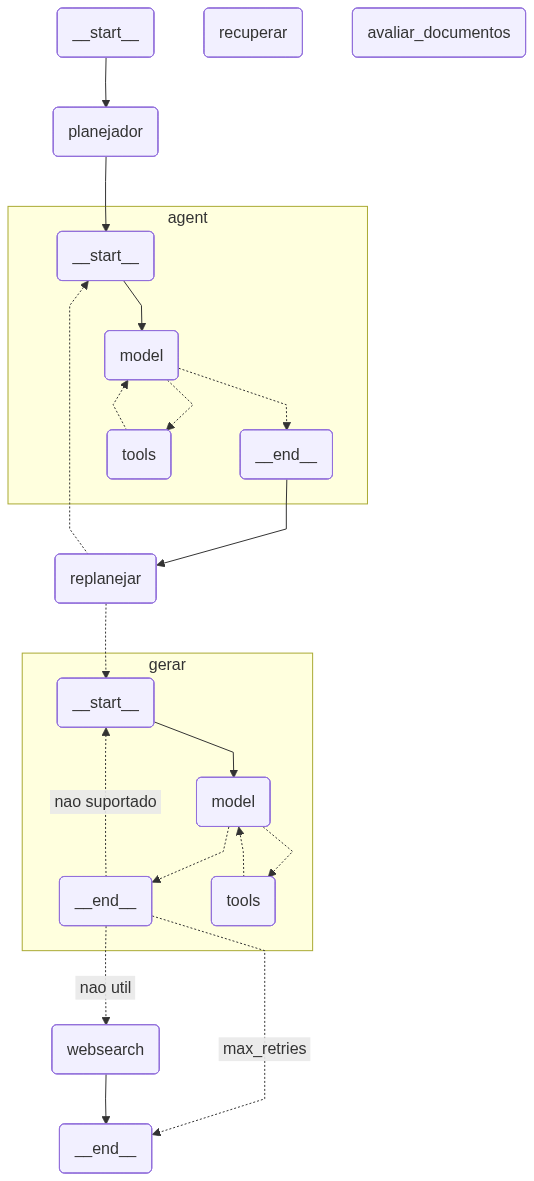

In [24]:
from IPython.display import Image, display

display(Image(app.get_graph(xray=True).draw_mermaid_png()))


In [25]:
config = {"recursion_limit": 50}
pergunta = "Meu computador com Windows 11 está bloqueando a execução do nosso ERP. Qual prática do ITIL v4 é mais relevante para resolver o problema?"

inputs = {"input": pergunta, "max_retries": 3}  # estado inicial

async for event in app.astream(inputs, config=config):
    for k, v in event.items():
        if k != "__end__":
            print(f"\n--- Nó: {k} ---")
            print(v)


--- Nó: planejador ---
{'plan': Plan(steps=['Analisar a situação descrita como uma interrupção não planejada de um serviço de TI (o ERP bloqueado).', 'Identificar a prática do ITIL v4 cujo propósito principal é restaurar a operação normal do serviço o mais rápido possível e minimizar o impacto negativo nas operações de negócio.', 'Concluir que a Gestão de Incidentes (Incident Management) é a prática mais relevante para resolver o problema imediato de bloqueio do software.'])}


ChatGoogleGenerativeAIError: Error calling model 'gemini-3-flash-preview' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-3-flash\nPlease retry in 34.610131204s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://ai.google.dev/gemini-api/docs/rate-limits'}]}, {'@type': 'type.googleapis.com/google.rpc.QuotaFailure', 'violations': [{'quotaMetric': 'generativelanguage.googleapis.com/generate_content_free_tier_requests', 'quotaId': 'GenerateRequestsPerDayPerProjectPerModel-F

In [ ]:
# from langchain_core.messages import HumanMessage

# async def avaliar_tickets_similares(descricao_problema: str):
#     print(f"🔍 Buscando tickets similares a: '{descricao_problema}'...")
    
#     # 1. Recuperar os tickets relevantes do seu vectorstore de 22k tickets
#     # Usamos o recuperadorTickets que você instanciou lá no início do notebook
#     tickets_recuperados = await recuperadorTickets.ainvoke(descricao_problema)
    
#     if not tickets_recuperados:
#         return "Nenhum ticket similar encontrado na base."

#     # 2. Formatar os tickets recuperados em um único bloco de texto
#     # Pegamos o page_content de cada documento retornado
#     texto_dos_tickets = "\n\n---\n\n".join(
#         [f"TICKET {i+1}:\n{doc.page_content}" for i, doc in enumerate(tickets_recuperados)]
#     )
    
#     # 3. Montar o Prompt para o Agente
#     # Aqui você instrui o agente sobre o que fazer com essa massa de dados
#     prompt_avaliacao = f"""Você é um especialista em Service Desk e ITIL v4.
# Abaixo estão alguns tickets históricos do nosso sistema que são similares ao problema atual.

# PROBLEMA ATUAL:
# {descricao_problema}

# TICKETS HISTÓRICOS RECUPERADOS:
# {texto_dos_tickets}

# SUA TAREFA:
# 1. Analise os tickets históricos acima.
# 2. Identifique qual foi a solução ou padrão de solução aplicado neles.
# 3. Com base neles e no seu conhecimento, Indique qual ou quais prática da ITIL v4 deve ser aplicada para gerenciar/evitar esse problema.
# """

#     print("🤖 Enviando tickets para avaliação do Agente...\n")
    
#     # 4. Enviar o prompt formatado para o seu AgentExecutor
#     # No seu código, você usou a chave "messages" com uma tupla ("user", conteudo)
#     resposta = await agent_executor.ainvoke(
#         {"messages": [("user", prompt_avaliacao)]}
#     )
    
#     # Retorna o conteúdo da última mensagem gerada pelo agente
#     return resposta["messages"][-1].content

# # --- TESTANDO ---
# # Rode isso numa célula assíncrona (ou apenas chame a função se estiver no Jupyter)
# descricao = "Avalie os tickets e recomende praticas de GSTI que iriam resolver os tickets"

# resultado = await avaliar_tickets_similares(descricao)
# print(resultado)

In [ ]:
# async def recuperar(state: PlanExecute):
#     """Recupera documentos do vectorstore de tickets históricos"""
#     print("---RECUPERAR TICKETS HISTÓRICOS---")
#     question = state["input"]
    
#     # Mudando para o seu recuperador de tickets!
#     documents = await recuperadorTickets.ainvoke(question) 
    
#     return {"documents": documents}